## Part 1: Setup and data loading

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Upload the healthcare dataset
from google.colab import files

uploaded = files.upload()

Saving 1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv to 1776250375-P2-Healthcare Analytics for Doctor Visits (1) (1).csv


In [3]:
# Load the dataset
import io

file_name = next(iter(uploaded))

data = pd.read_csv(io.BytesIO(uploaded[file_name]))

data.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [5]:
# Display the last five rows
data.tail()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


##  Part 2: Data overview

In [6]:
# Display dataset dimensions
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

Number of rows: 5190
Number of columns: 13


In [7]:
# Display column names
print("Healthcare dataset columns:")

for column in data.columns:
    print(column)

Healthcare dataset columns:
Unnamed: 0
visits
gender
age
income
illness
reduced
health
private
freepoor
freerepat
nchronic
lchronic


In [8]:
# Inspect data types and non-null values
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [9]:
# Generate descriptive statistics
data.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [10]:
# Summarize categorical variables
data.describe(include='object')

,gender,private,freepoor,freerepat,nchronic,lchronic
count,5190,5190,5190,5190,5190,5190
unique,2,2,2,2,2,2
top,female,no,no,no,no,no
freq,2702,2892,4968,4099,3098,4585


## Part 3: Data cleaning

In [11]:
# Check missing values
data.isnull().sum()

,0
Unnamed: 0,0
visits,0
gender,0
age,0
income,0
illness,0
reduced,0
health,0
private,0
freepoor,0


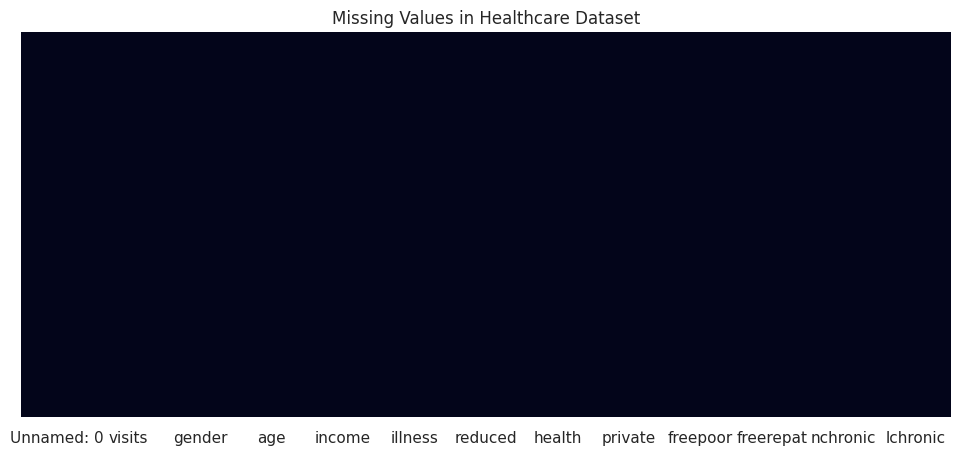

In [12]:
# Visualize missing values
plt.figure(figsize=(12, 5))

sns.heatmap(
    data.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Healthcare Dataset")
plt.show()

In [13]:
# Check duplicate records
print("Duplicate records:", data.duplicated().sum())

Duplicate records: 0


In [14]:
# Remove duplicates and row identifier
data = data.drop_duplicates().copy()

data.drop(
    columns=['Unnamed: 0'],
    errors='ignore',
    inplace=True
)

print("Dataset shape after cleaning:", data.shape)

Dataset shape after cleaning: (5190, 12)


## Part 4: Exploratory data analysis

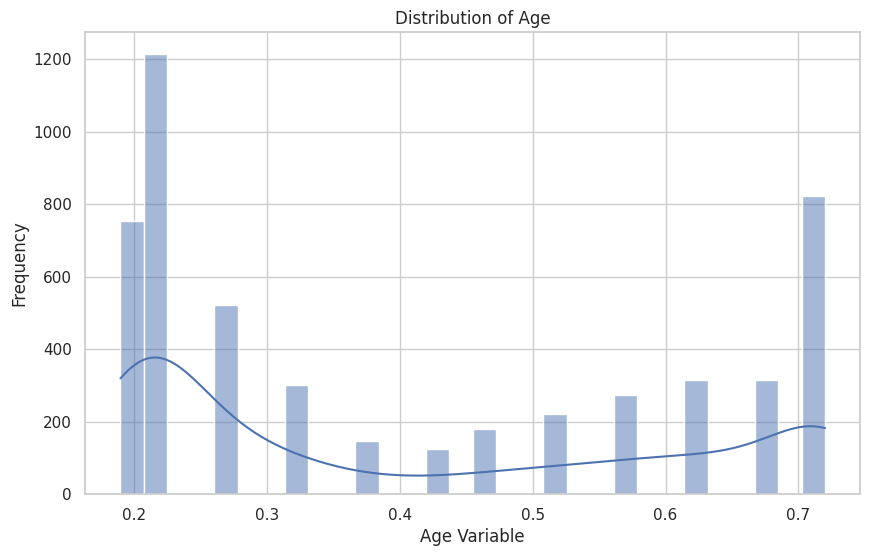

In [15]:
# Distribution of age
plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x='age',
    bins=30,
    kde=True
)

plt.title("Distribution of Age")
plt.xlabel("Age Variable")
plt.ylabel("Frequency")
plt.show()

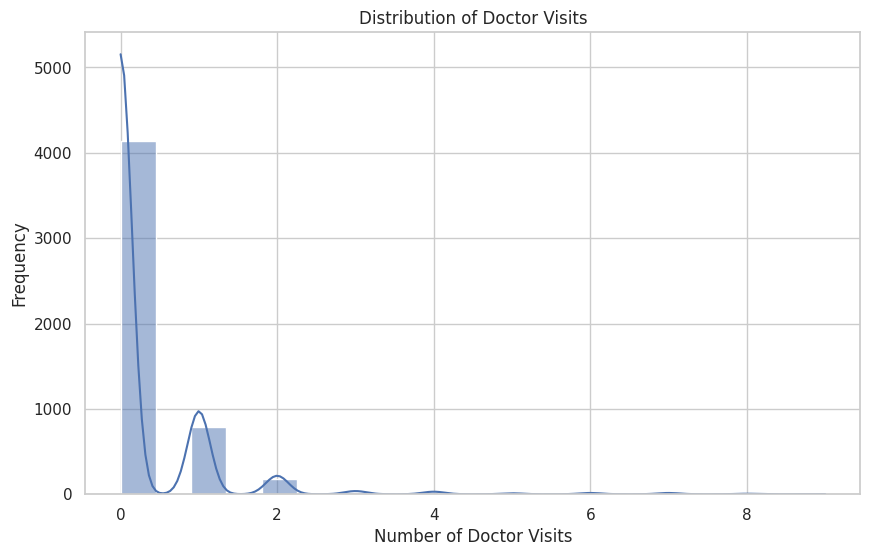

In [16]:
# Distribution of doctor visits
plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x='visits',
    bins=20,
    kde=True
)

plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of Doctor Visits")
plt.ylabel("Frequency")
plt.show()

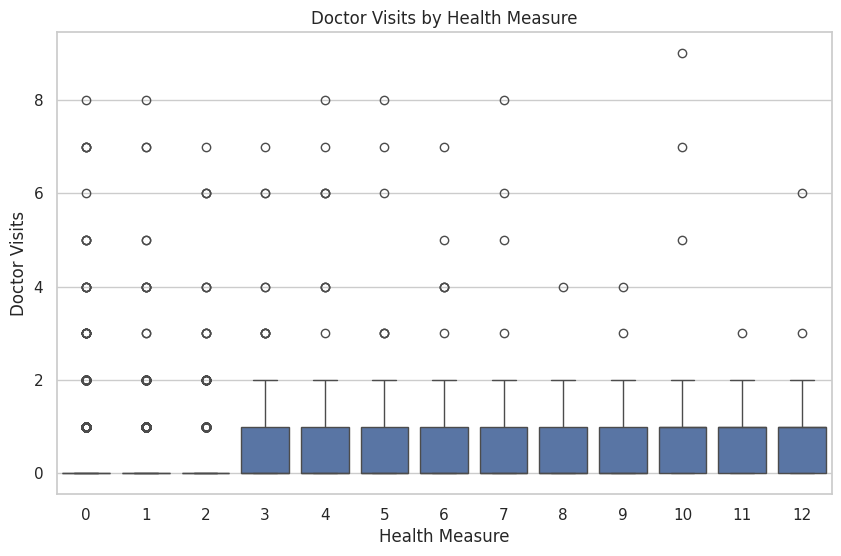

In [17]:
# Doctor visits by health status
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='health',
    y='visits'
)

plt.title("Doctor Visits by Health Measure")
plt.xlabel("Health Measure")
plt.ylabel("Doctor Visits")
plt.show()

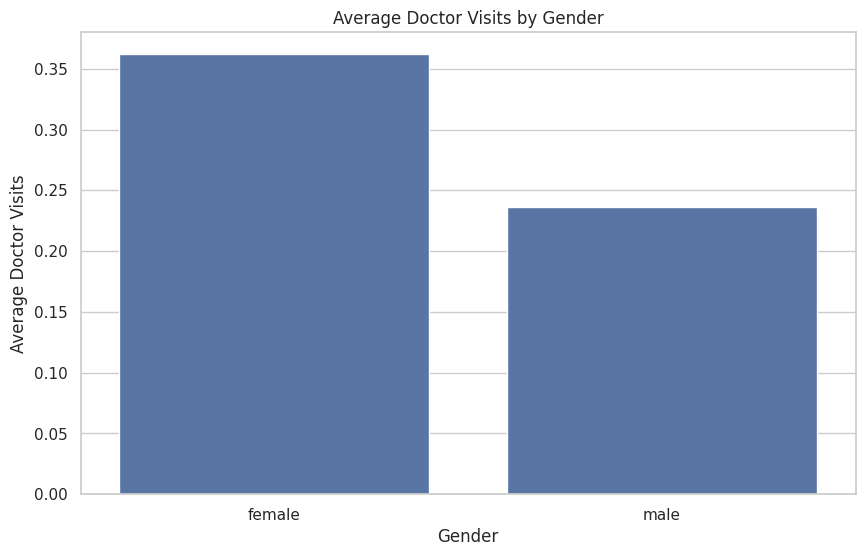

In [18]:
# Doctor visits by gender
plt.figure(figsize=(10, 6))

sns.barplot(
    data=data,
    x='gender',
    y='visits',
    errorbar=None
)

plt.title("Average Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Doctor Visits")
plt.show()

## Part 5: Further exploratory analysis

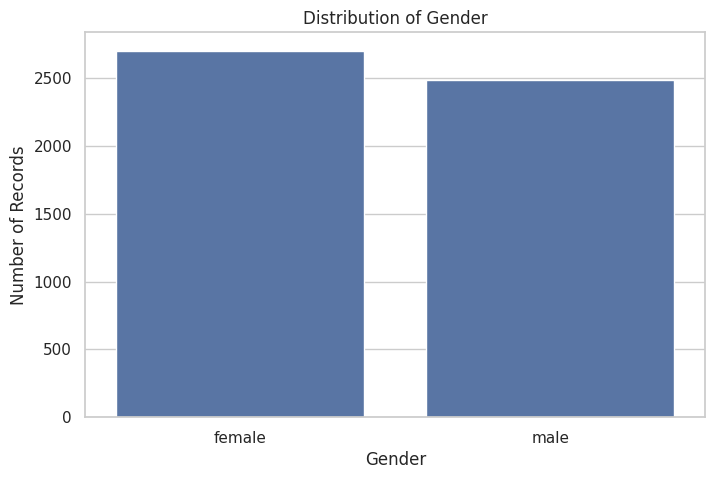

In [19]:
# Distribution of gender
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x='gender'
)

plt.title("Distribution of Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Records")
plt.show()

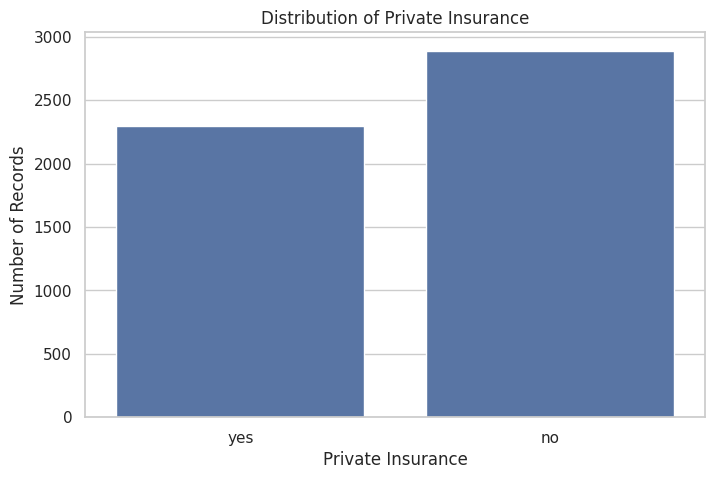

In [20]:
# Distribution of private insurance
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x='private'
)

plt.title("Distribution of Private Insurance")
plt.xlabel("Private Insurance")
plt.ylabel("Number of Records")
plt.show()

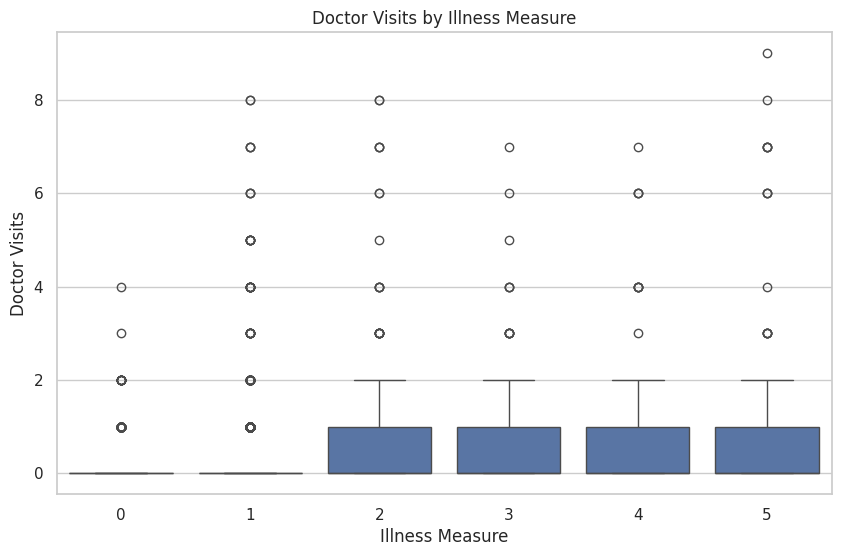

In [21]:
# Illness measure versus doctor visits
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='illness',
    y='visits'
)

plt.title("Doctor Visits by Illness Measure")
plt.xlabel("Illness Measure")
plt.ylabel("Doctor Visits")
plt.show()

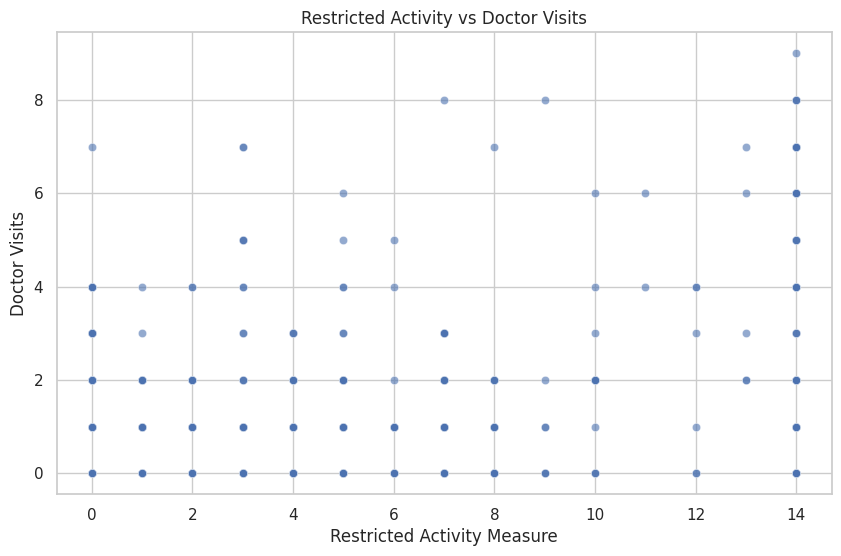

In [22]:
# Restricted activity versus doctor visits
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x='reduced',
    y='visits',
    alpha=0.6
)

plt.title("Restricted Activity vs Doctor Visits")
plt.xlabel("Restricted Activity Measure")
plt.ylabel("Doctor Visits")
plt.show()

## Part 6: Multivariate analysis

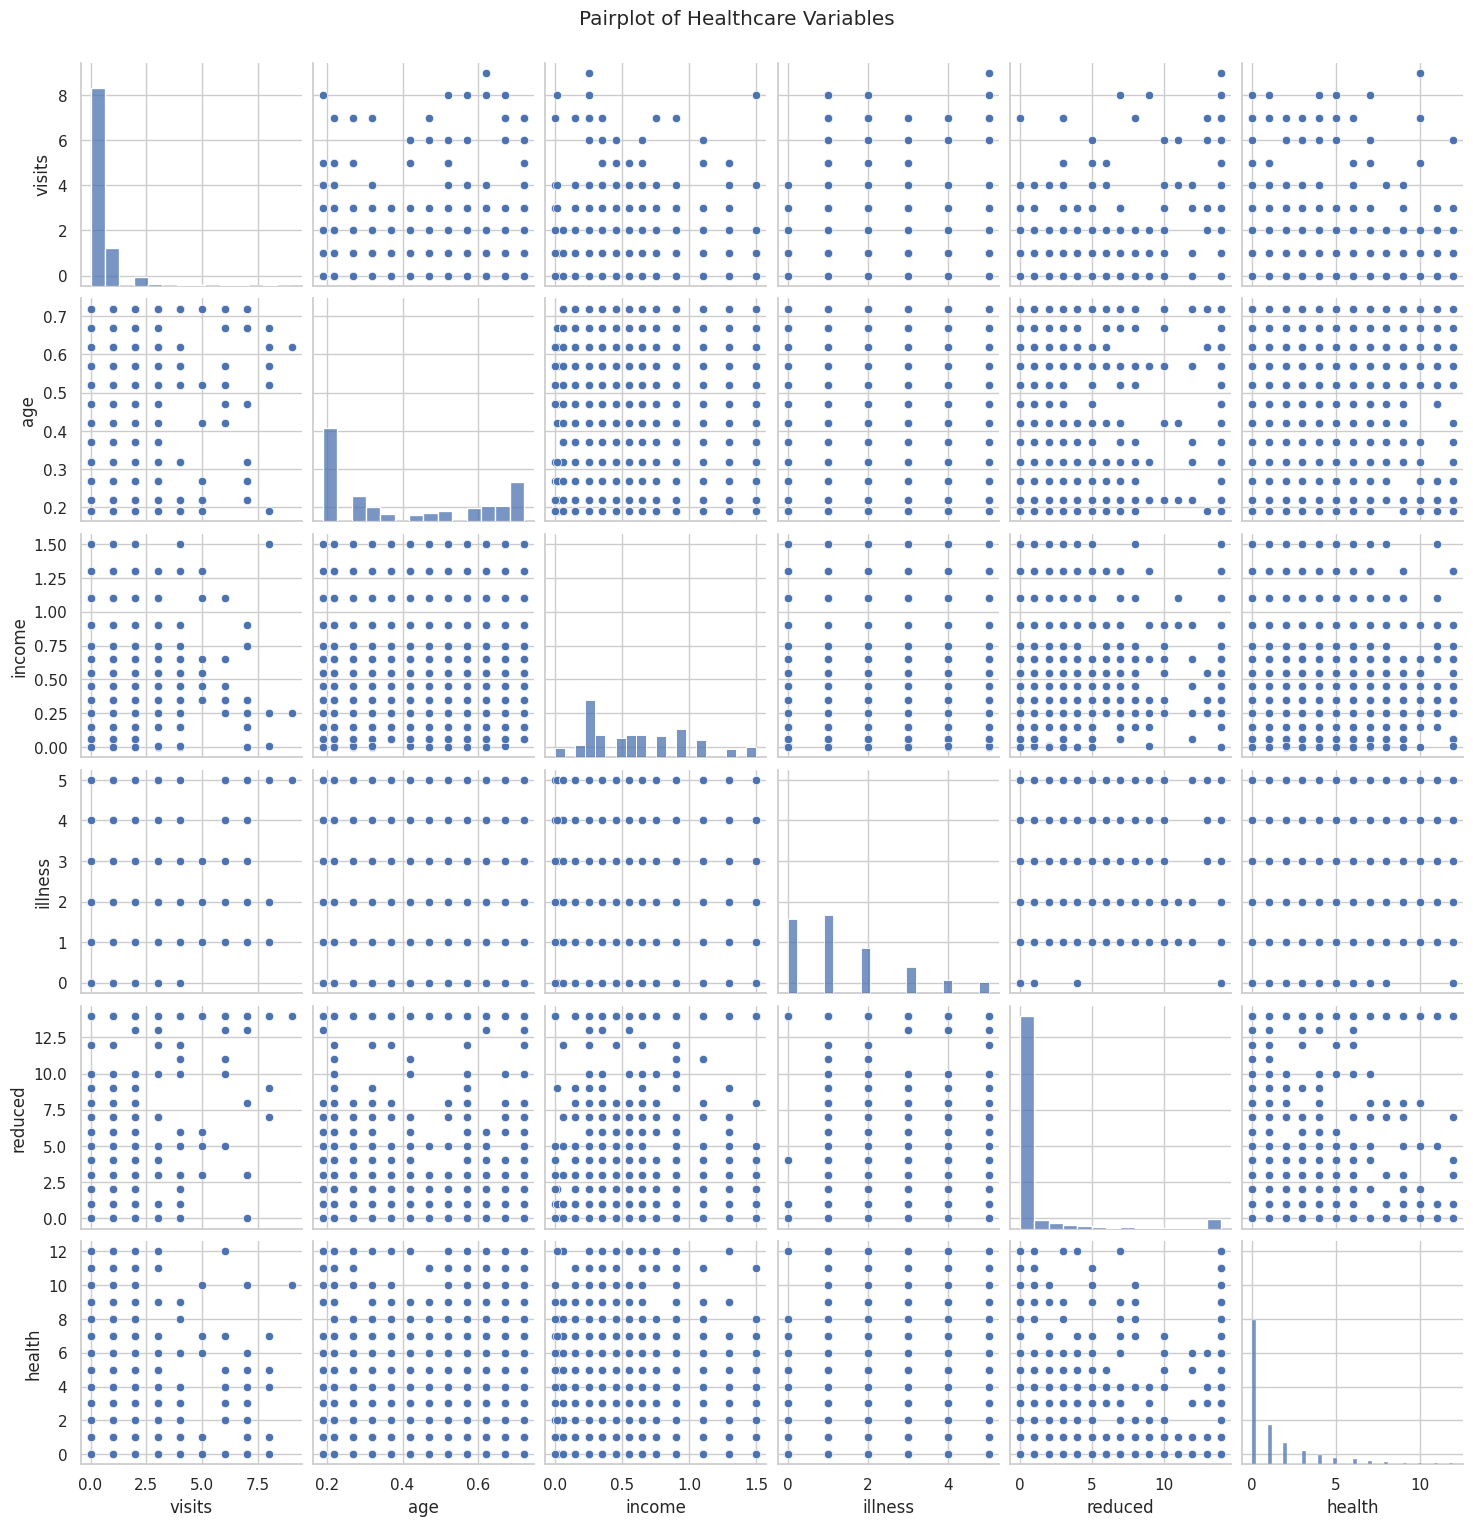

In [23]:
# Pairplot of numerical variables
features = [
    'visits',
    'age',
    'income',
    'illness',
    'reduced',
    'health'
]

sns.pairplot(
    data[features].dropna(),
    diag_kind='hist'
)

plt.suptitle(
    "Pairplot of Healthcare Variables",
    y=1.02
)

plt.show()

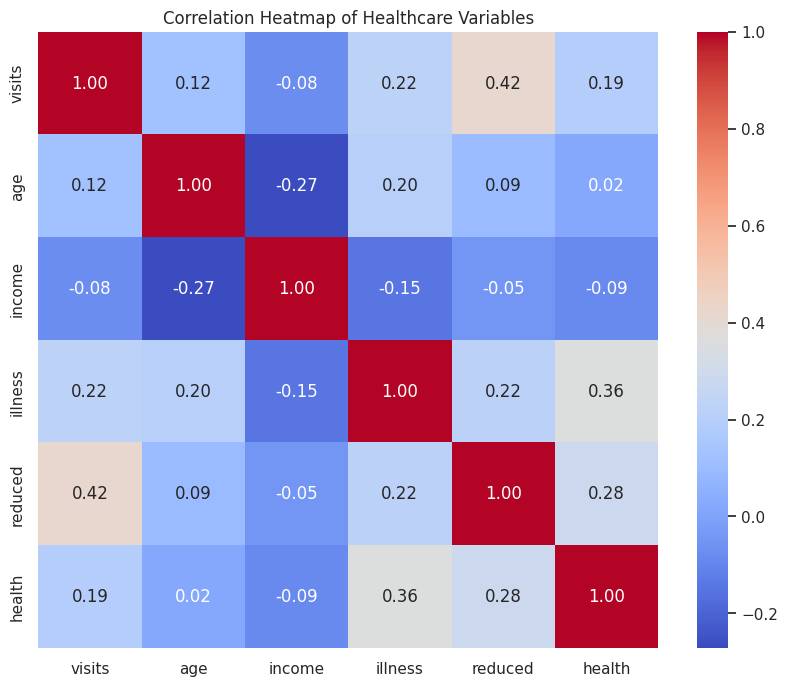

In [24]:
# Correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Healthcare Variables")
plt.show()

## Part 7: Save the cleaned dataset

In [25]:
# Export the cleaned data
data.to_csv(
    'healthcare_doctor_visits_cleaned.csv',
    index=False
)

print("Cleaned healthcare dataset saved successfully.")

Cleaned healthcare dataset saved successfully.


In [26]:
# Download the CSV
from google.colab import files

files.download('healthcare_doctor_visits_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Part 8 — Linear Regression and Random Forest Prediction

In [27]:
# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Machine learning libraries imported successfully.")

Machine learning libraries imported successfully.


In [28]:
# Prepare the data for prediction
# Separate input features and target variable
# Create a copy for machine learning
model_data = data.copy()

# Remove rows where target is missing
model_data = model_data.dropna(subset=['visits'])

# Remove invalid negative visit counts
model_data = model_data[model_data['visits'] >= 0]

# Separate features and target
X = model_data.drop(columns=['visits'])
y = model_data['visits']

# Remove row identifier if present
X = X.drop(columns=['Unnamed: 0'], errors='ignore')

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

display(X.head())

Input features shape: (5190, 11)
Target variable shape: (5190,)


,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,male,0.19,0.90,3,0,0,no,no,no,no,no
3,male,0.19,0.15,1,0,0,no,no,no,no,no
4,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [29]:
# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'income', 'illness', 'reduced', 'health']

Categorical features:
['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']


In [30]:
#  Handle missing values and encode categorical data
# Create preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numeric_transformer, numeric_features),
        ('categorical', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [31]:
# Split training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4152
Testing records: 1038


In [32]:
# Train Linear Regression
# Build and train the model
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [33]:
# Generate predictions
linear_predictions = linear_model.predict(X_test)

linear_predictions = np.maximum(
    linear_predictions, 0
)

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(np.round(linear_predictions[:10], 2))

First 10 actual values:
[0 4 0 0 0 0 0 0 1 0]

First 10 predicted values:
[0.2  0.41 0.36 0.12 0.15 0.05 0.18 0.14 0.32 0.19]


In [34]:
# Train Random Forest Regression
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [35]:
# Generate predictions
rf_predictions = rf_model.predict(X_test)

rf_predictions = np.maximum(
    rf_predictions, 0
)

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(np.round(rf_predictions[:10], 2))

First 10 actual values:
[0 4 0 0 0 0 0 0 1 0]

First 10 predicted values:
[0.53 1.22 0.41 0.06 0.03 0.08 0.68 0.12 0.26 0.46]


## Part 9 — Performance Evaluation and Data Export

In [36]:
# Evaluate Linear Regression
# Calculate performance metrics
# Use the original model outputs for evaluation
linear_raw_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test, linear_raw_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_raw_predictions)
)

linear_r2 = r2_score(
    y_test, linear_raw_predictions
)

print("LINEAR REGRESSION PERFORMANCE")
print("-" * 35)
print("MAE:", round(linear_mae, 3))
print("RMSE:", round(linear_rmse, 3))
print("R2 Score:", round(linear_r2, 3))

LINEAR REGRESSION PERFORMANCE
-----------------------------------
MAE: 0.42
RMSE: 0.835
R2 Score: 0.212


In [37]:
# Evaluate Random Forest
rf_raw_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test, rf_raw_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_raw_predictions)
)

rf_r2 = r2_score(
    y_test, rf_raw_predictions
)

print("RANDOM FOREST PERFORMANCE")
print("-" * 35)
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

RANDOM FOREST PERFORMANCE
-----------------------------------
MAE: 0.428
RMSE: 0.869
R2 Score: 0.146


In [38]:
# Compare the models
comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest Regression'
    ],
    'MAE': [
        linear_mae,
        rf_mae
    ],
    'RMSE': [
        linear_rmse,
        rf_rmse
    ],
    'R2 Score': [
        linear_r2,
        rf_r2
    ]
})

display(comparison.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.420,0.835,0.212
1,Random Forest Regression,0.428,0.869,0.146


Interpretation:
- Lower MAE indicates a smaller average absolute prediction error.
- Lower RMSE indicates a smaller error with greater penalty for large mistakes.
- Higher R² generally indicates better explanatory performance on the test set.

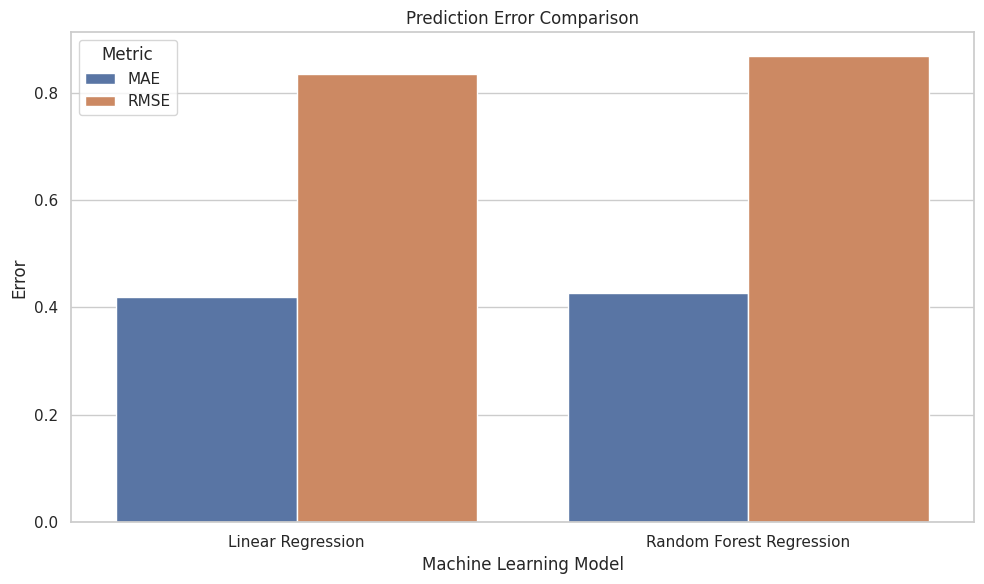

In [39]:
# Visualize model comparison
comparison_plot = comparison.melt(
    id_vars='Model',
    value_vars=['MAE', 'RMSE'],
    var_name='Metric',
    value_name='Error'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x='Model',
    y='Error',
    hue='Metric'
)

plt.title("Prediction Error Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Error")
plt.tight_layout()
plt.show()

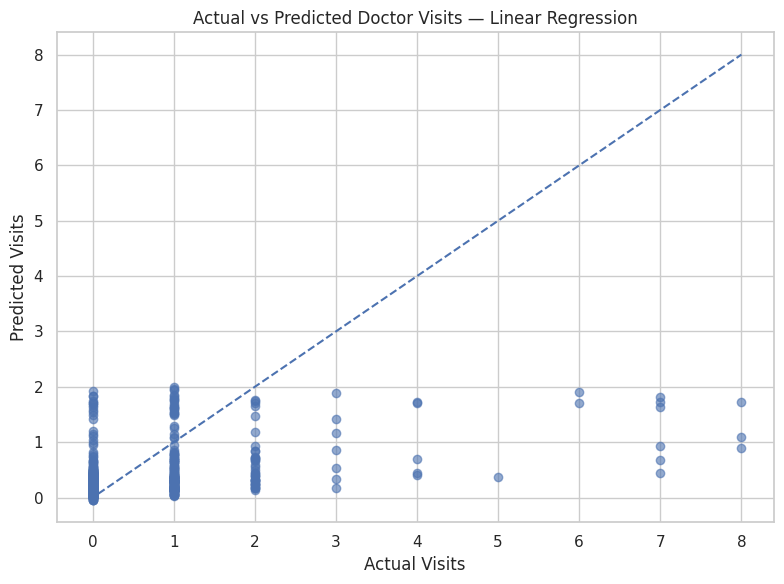

In [40]:
# Plot actual versus predicted visits
# Linear Regression
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    linear_raw_predictions,
    alpha=0.6
)

lower = min(y_test.min(), linear_raw_predictions.min())
upper = max(y_test.max(), linear_raw_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle='--'
)

plt.title("Actual vs Predicted Doctor Visits — Linear Regression")
plt.xlabel("Actual Visits")
plt.ylabel("Predicted Visits")
plt.tight_layout()
plt.show()

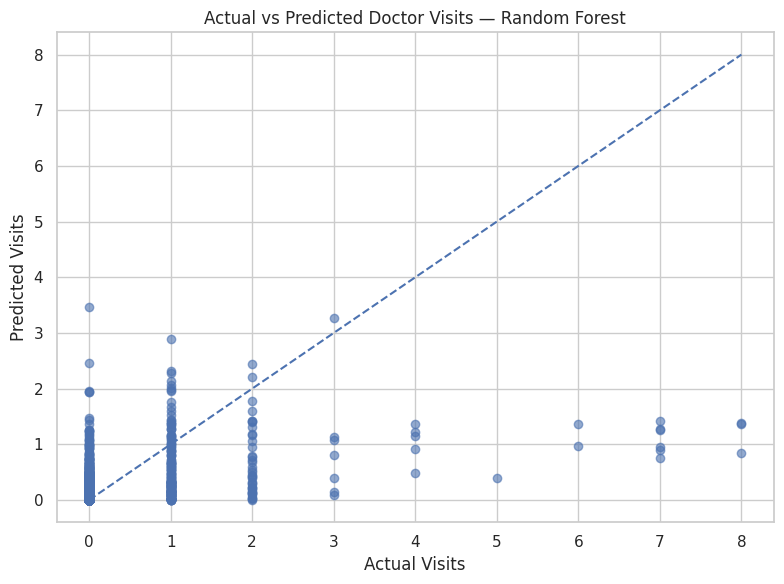

In [41]:
# Random Forest
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_raw_predictions,
    alpha=0.6
)

lower = min(y_test.min(), rf_raw_predictions.min())
upper = max(y_test.max(), rf_raw_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle='--'
)

plt.title("Actual vs Predicted Doctor Visits — Random Forest")
plt.xlabel("Actual Visits")
plt.ylabel("Predicted Visits")
plt.tight_layout()
plt.show()

In [42]:
# Identify important features
# Extract Random Forest feature importance
fitted_preprocessor = rf_model.named_steps['preprocessor']
fitted_rf = rf_model.named_steps['regressor']

feature_names = fitted_preprocessor.get_feature_names_out()
feature_importances = fitted_rf.feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(
    by='Importance',
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
3,numerical__reduced,0.304708
4,numerical__health,0.154063
1,numerical__income,0.134942
0,numerical__age,0.132187
2,numerical__illness,0.114298
7,categorical__private_no,0.020073
8,categorical__private_yes,0.019518
14,categorical__nchronic_yes,0.018693
5,categorical__gender_female,0.018079
13,categorical__nchronic_no,0.017700


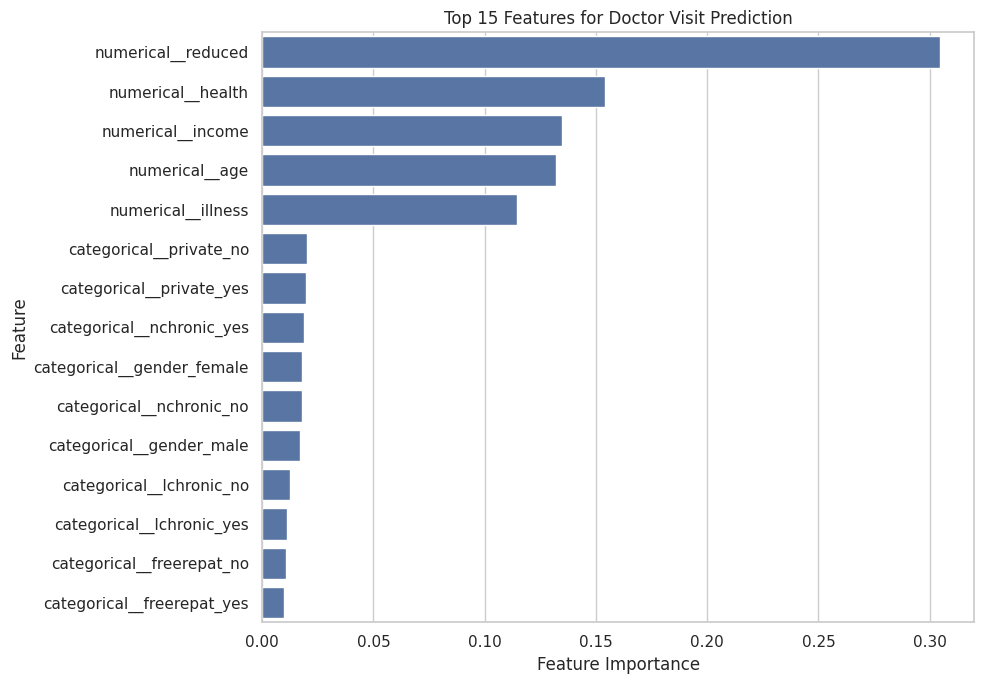

In [43]:
# Visualize the top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Features for Doctor Visit Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [44]:
# Export predictions
# Create a prediction results table
prediction_results = pd.DataFrame({
    'Actual_Visits': y_test.to_numpy(),
    'Linear_Regression_Predicted': linear_raw_predictions,
    'Random_Forest_Predicted': rf_raw_predictions
})

display(prediction_results.head(10))

,Actual_Visits,Linear_Regression_Predicted,Random_Forest_Predicted
0,0,0.203300,0.532530
1,4,0.412128,1.216952
2,0,0.360172,0.408798
3,0,0.118589,0.060583
4,0,0.145205,0.031643
5,0,0.047432,0.076674
6,0,0.180532,0.675379
7,0,0.141484,0.120486
8,1,0.315804,0.255554
9,0,0.191108,0.457606


In [45]:
# Final project summary
print("=" * 50)
print("HEALTHCARE ANALYTICS PROJECT SUMMARY")
print("=" * 50)

print("Dataset records:", len(data))
print("Dataset variables:", data.shape[1])

print("\nLinear Regression:")
print("MAE:", round(linear_mae, 3))
print("RMSE:", round(linear_rmse, 3))
print("R2 Score:", round(linear_r2, 3))

print("\nRandom Forest Regression:")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

best_model_name = (
    "Linear Regression"
    if linear_mae < rf_mae
    else "Random Forest Regression"
)

print("\nModel with lower test MAE:", best_model_name)
print("\nProject execution completed.")

HEALTHCARE ANALYTICS PROJECT SUMMARY
Dataset records: 5190
Dataset variables: 12

Linear Regression:
MAE: 0.42
RMSE: 0.835
R2 Score: 0.212

Random Forest Regression:
MAE: 0.428
RMSE: 0.869
R2 Score: 0.146

Model with lower test MAE: Linear Regression

Project execution completed.
